# Complete five-league real-data pipeline

New models are actually fitted on real FBref observations from La Liga, Premier League, Bundesliga, Serie A and Ligue1. Every prior source, table and model artifact is preserved. Market values/profile enrichment remain private, provisional review data and do not enter fitting. This notebook analyses executed experiments; no synthetic player data or transfer-success results are introduced.

In [1]:
from pathlib import Path
import os,sys,json
ROOT=Path.cwd()
while not (ROOT/'src/config.py').exists():
    if ROOT==ROOT.parent:raise RuntimeError('Run inside the repository')
    ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display,Markdown,Image
from src.data.provenance import sha256
folder=ROOT/'reports/five_league_pipeline'
report=json.loads((folder/'pipeline.json').read_text())
for item in report['outputs'].values():assert sha256(ROOT/item['path'])==item['sha256']
display(pd.DataFrame(report['counts'].items(),columns=['table','rows']))
display(Markdown('Dataset version `'+report['dataset_version']+'`; training code commit `'+report['git_commit']+'`.'))


,table,rows
0,player_club_seasons,16334
1,player_seasons,15948
2,core_gallery,7398
3,offensive_gallery,9198


Dataset version `d7a70a7349eb58b62cd18c540129203cd411aeb97706cdf074cbcbe74f8ad49a`; training code commit `f5eb8225cb01c77ecb8795312e0f29f82d9166b1`.

## Identity, cleaning and season-aware preprocessing

Source FBref player ID identifies a person; observation keys also include league, season and club. Club stints sum only inside a league-season; any missing stint total leaves the seasonal total unknown. For a gallery, cross-league transfers select the highest-minute league before feature eligibility, never merge league rates. Exact duplicates are removed; conflicting identity keys stop. Numeric/age/unit checks preserve missing values, and auxiliary source totals require period-compatible exposure. Unknown values are never substituted with zero. 2025/26 is partial and never fitted. Core advanced2024/25 is too sparse for a usable gallery. The full field dictionary and source coverage describe retained fields, not absent statistics.

In [2]:
display(pd.read_csv(folder/'alignment.csv').groupby(['league','category']).agg(stints=('stints','sum'),matched=('matched','sum'),compatible=('compatible','sum')))
missing=pd.read_csv(folder/'missingness.csv')
display(missing[missing.table.eq('player_seasons')].sort_values('missing_fraction',ascending=False).head(25))
display(pd.read_csv(folder/'season_position_quality.csv'))


stints  matched  compatible
league         category                               
Bundesliga     defense       2898     2429        2064
               misc          2898     2429        2064
               passing       2898     2898        2898
               possession    2898     2429        2064
               shooting      2898     2898        2898
La Liga        defense       3443     2874        2434
               misc          3443     2874        2434
               passing       3443     3443        3434
               possession    3443     2874        2434
               shooting      3443     3443        3443
Ligue 1        defense       3276     2750        2372
               misc          3276     2750        2372
               passing       3276     3276        3275
               possession    3276     2750        2372
               shooting      3276     3276        3275
Premier League defense       3205     2666        2254
               misc          3205     2666        2254
               passing       3205     3205        3205
               possession    3205     2666        2254
               shooting      3205     3205        3205
Serie A        defense       3512     2945        2508
               misc          3512     2945        2508
               passing       3512     3512        3512
               possession    3512     2945        2508
               shooting      3512     3512        3512

,table,field,missing,missing_fraction
122,player_seasons,valuation_date,15948,1.000000
124,player_seasons,valuation_source,15948,1.000000
112,player_seasons,xa,15948,1.000000
127,player_seasons,knowledge_date,15948,1.000000
117,player_seasons,date_of_birth,15948,1.000000
120,player_seasons,market_value_eur,15948,1.000000
119,player_seasons,foot,15948,1.000000
121,player_seasons,currency,15948,1.000000
142,player_seasons,xa_p90,15948,1.000000
118,player_seasons,height_cm,15948,1.000000


,league,season,pos_main,players,minutes_missing,eligible_baseline,eligible_core,multiclub,outliers
0,Bundesliga,2020-2021,DF,176,0,142,142,3,0
1,Bundesliga,2020-2021,FW,132,0,88,88,2,1
2,Bundesliga,2020-2021,GK,35,0,0,0,0,0
3,Bundesliga,2020-2021,MF,153,0,108,108,4,0
4,Bundesliga,2021-2022,DF,185,0,140,140,7,1
...,...,...,...,...,...,...,...,...,...
116,Serie A,2024-2025,MF,190,0,129,0,8,1
117,Serie A,2025-2026,DF,151,0,0,0,1,0
118,Serie A,2025-2026,FW,91,0,0,0,0,3
119,Serie A,2025-2026,GK,23,0,0,0,0,0


## EDA: distributions, outliers, correlation and cohort differences

Plots use observed complete-season profiles with at least450minutes for per90 comparisons. IQR reference limits use 2020/21–2021/22 development years and flag tails without deleting rows or clipping values. Boxplots suppress visual fliers only; observations stay in data and models. Spearman correlations use available pairs, not global imputation. G+A is redundant and excluded from the nine-feature Core fit. Comparisons across roles/leagues/seasons describe coverage-selected cohorts, not causal league quality.

,Unnamed: 0,count,mean,std,min,1%,25%,50%,75%,99%,max
0,minutes,9983.0,1717.848943,788.564891,450.0,471.0,1045.000000,1654.000000,2354.500000,3331.080000,3420.000000
1,gls_p90,9983.0,0.124453,0.166045,0.0,0.0,0.000000,0.064057,0.180905,0.720663,1.501221
2,ast_p90,9983.0,0.087746,0.104609,0.0,0.0,0.000000,0.058843,0.140078,0.432813,0.830376
3,sh_p90,9983.0,1.162649,0.947512,0.0,0.0,0.429492,0.881844,1.785525,3.816220,5.686404
4,sot_p90,9983.0,0.387771,0.390952,0.0,0.0,0.092736,0.248276,0.596168,1.575360,2.549133
5,crs_p90,8013.0,1.644340,1.901646,0.0,0.0,0.190517,0.873786,2.571429,8.083997,13.168121
6,int_p90,8013.0,0.882614,0.607783,0.0,0.0,0.381356,0.842939,1.285714,2.491086,4.135667
7,tklw_p90,8013.0,0.886810,0.524527,0.0,0.0,0.517837,0.865385,1.223404,2.256160,3.410526
8,fls_p90,8013.0,1.169515,0.630105,0.0,0.0,0.770548,1.132788,1.538462,2.902886,4.596774
9,fld_p90,8013.0,1.095130,0.723791,0.0,0.0,0.552486,0.989651,1.509740,3.212999,6.203390


observed  flagged
league         feature                    
Bundesliga     ast_p90       1766       54
               crs_p90       1415       74
               fld_p90       1415       38
               fls_p90       1415       18
               gls_p90       1766       91
               int_p90       1415        3
               minutes       1766        0
               sh_p90        1766       17
               sot_p90       1766       49
               tklw_p90      1415        9
La Liga        ast_p90       2126       65
               crs_p90       1696       29
               fld_p90       1696       32
               fls_p90       1696       36
               gls_p90       2126      129
               int_p90       1696        2
               minutes       2126        0
               sh_p90        2126       46
               sot_p90       2126      102
               tklw_p90      1696       42
Ligue 1        ast_p90       1959       70
               crs_p90       1595       62
               fld_p90       1595       32
               fls_p90       1595       26
               gls_p90       1959      108
               int_p90       1595        3
               minutes       1959        0
               sh_p90        1959       18
               sot_p90       1959       53
               tklw_p90      1595       13
Premier League ast_p90       2006       67
               crs_p90       1607       67
               fld_p90       1607       39
               fls_p90       1607       21
               gls_p90       2006      137
               int_p90       1607        2
               minutes       2006        0
               sh_p90        2006       18
               sot_p90       2006       57
               tklw_p90      1607       18
Serie A        ast_p90       2126       40
               crs_p90       1700       47
               fld_p90       1700       23
               fls_p90       1700       22
               gls_p90       2126      113
               int_p90       1700        6
               minutes       2126        0
               sh_p90        2126       30
               sot_p90       2126       35
               tklw_p90      1700       25

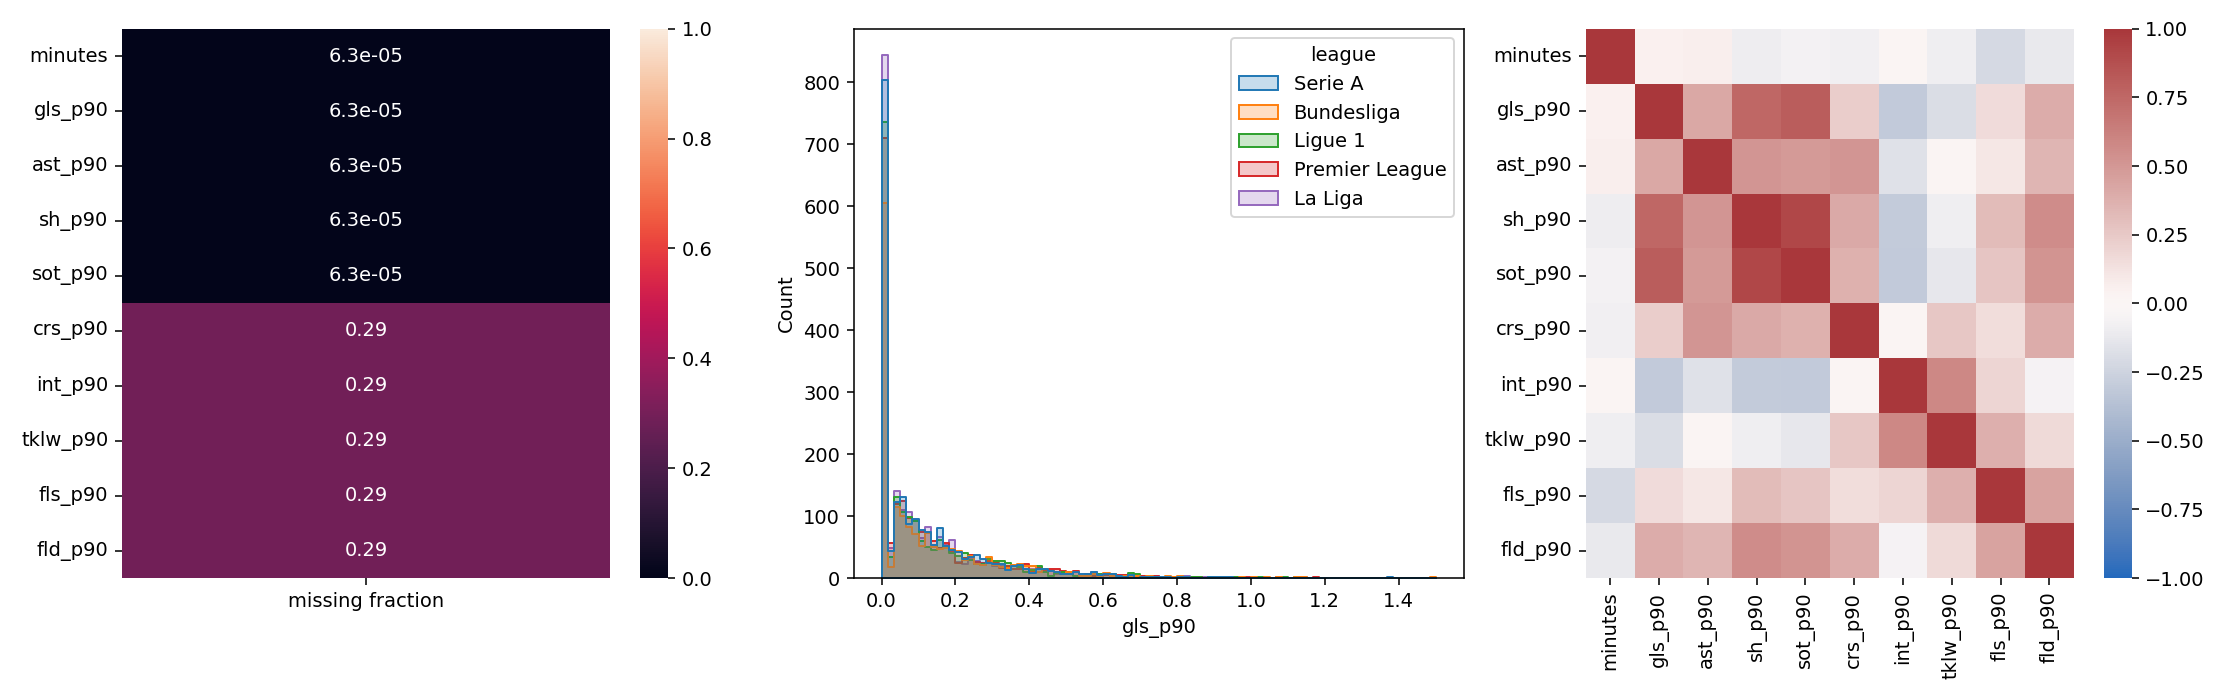

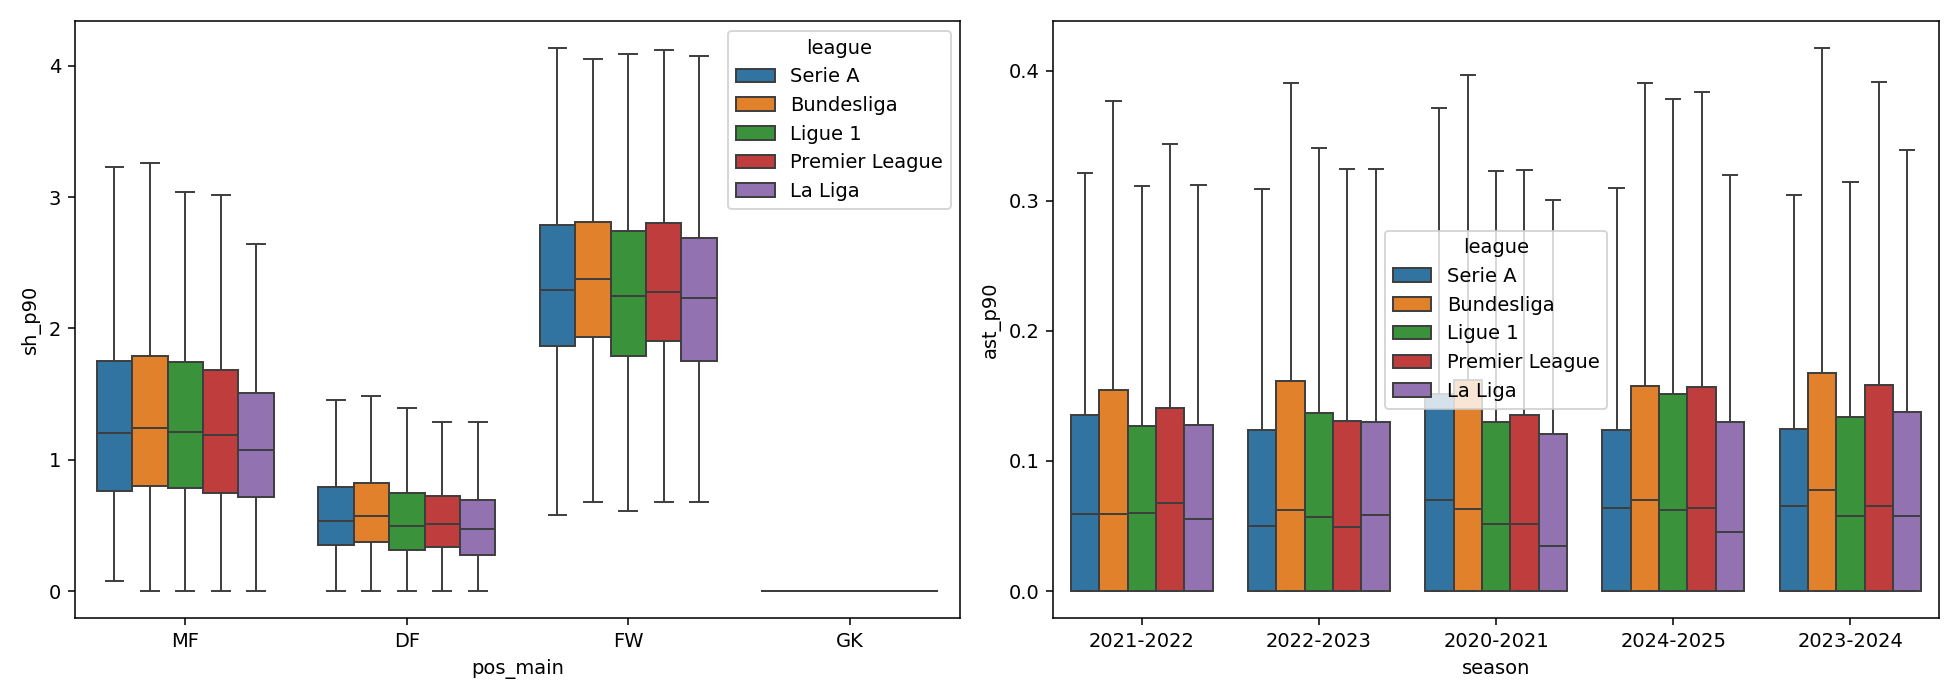

In [3]:
display(pd.read_csv(folder/'distributions.csv'))
display(pd.read_csv(folder/'outliers.csv').groupby(['league','feature']).agg(observed=('observed','sum'),flagged=('outside','sum')))
display(Image(filename=str(folder/'eda_quality.png')))
display(Image(filename=str(folder/'eda_cohorts.png')))


## Chronological experiments and meaningful baselines

Core trains2020/21–2021/22, validates2022/23 and holds out2023/24. Offensive trains through2022/23, validates2023/24 and holds out2024/25. Attack-on-Core uses the Core cohort with offensive features. K is chosen using training silhouette; distance method is chosen on validation MRR. Imputer/scaler/PCA/clusters see training seasons only. The holdout is never tuned. Retrieval tests the same player’s next-season profile against the full future gallery, with goals/assists, goals-only and random baselines; ties use uniform expected ranks. Pooled galleries are much larger than the old La Liga-only pools.

In [4]:
summary=[]
for name,info in report['experiments'].items():
    summary.append(dict(model=name,**{key:info[key] for key in ['selected_method','selected_k','train_seasons','validation_season','holdout_season','holdout_mrr','holdout_recall_at_5','rows_by_split']}))
    metrics=pd.read_csv(folder/f'{name}_retrieval.csv')
    display(metrics[metrics.phase.eq('holdout')][['method','queries','candidate_count','mrr','mrr_ci_low','mrr_ci_high','recall_at_5','mrr_delta_goals_assists','mrr_delta_ci_low','mrr_delta_ci_high']])
display(pd.DataFrame(summary))
comparison=pd.read_csv(folder/'matched_pool_comparison.csv')
display(comparison)
display(Markdown('Matched-pool differences compare identical returning identities and candidates. Their paired bootstrap intervals, rather than the old single-league metric magnitude, determine whether an observed change is distinguishable from zero in this cohort. No improvement is assumed.'))


,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,mrr_delta_goals_assists,mrr_delta_ci_low,mrr_delta_ci_high
10,cluster_cosine,1240,1804,0.023586,0.019041,0.029474,0.025806,0.009586,0.004322,0.016711
11,cosine_profile,1240,1804,0.024626,0.020521,0.030092,0.025806,0.010627,0.005172,0.017206
12,euclidean_profile,1240,1804,0.031223,0.025888,0.038327,0.038710,0.017224,0.011129,0.023992
13,goals_assists,1240,1804,0.013999,0.010469,0.017937,0.013568,0.000000,0.000000,0.000000
14,goals_only,1240,1804,0.011219,0.008283,0.015274,0.008475,-0.002781,-0.006838,0.002065
15,pca2_cosine,1240,1804,0.013518,0.010835,0.016461,0.011290,-0.000481,-0.005518,0.003561
16,pca2_euclidean,1240,1804,0.019918,0.016337,0.024817,0.020161,0.005918,0.000041,0.011243
17,pca4_cosine,1240,1804,0.019770,0.016178,0.024492,0.020161,0.005770,0.000514,0.011222
18,pca4_euclidean,1240,1804,0.026984,0.022409,0.032866,0.032258,0.012984,0.007260,0.019539
19,random,1240,1804,0.006526,0.003968,0.009750,0.005645,-0.007474,-0.012400,-0.002628


,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,mrr_delta_goals_assists,mrr_delta_ci_low,mrr_delta_ci_high
10,cluster_cosine,1266,1810,0.082639,0.072407,0.094327,0.107425,0.072836,0.062489,0.085064
11,cosine_profile,1266,1810,0.084423,0.072648,0.097079,0.107425,0.074620,0.062733,0.087406
12,euclidean_profile,1266,1810,0.095498,0.083955,0.107772,0.129542,0.085696,0.073071,0.097672
13,goals_assists,1266,1810,0.009803,0.007566,0.012639,0.008542,0.000000,0.000000,0.000000
14,goals_only,1266,1810,0.007597,0.006234,0.009367,0.006082,-0.002206,-0.004553,-0.000395
15,pca2_cosine,1266,1810,0.020767,0.017038,0.025136,0.026066,0.010964,0.006481,0.015854
16,pca2_euclidean,1266,1810,0.031263,0.026142,0.038065,0.037915,0.021460,0.016241,0.027981
17,pca4_cosine,1266,1810,0.050653,0.043334,0.057152,0.061611,0.040851,0.033239,0.048292
18,pca4_euclidean,1266,1810,0.068793,0.060140,0.079661,0.088468,0.058990,0.050126,0.069031
19,random,1266,1810,0.004651,0.003407,0.006106,0.004739,-0.005152,-0.008120,-0.002254


,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,mrr_delta_goals_assists,mrr_delta_ci_low,mrr_delta_ci_high
10,cluster_cosine,1266,1810,0.020867,0.016428,0.025489,0.017378,0.011064,0.006900,0.015708
11,cosine_profile,1266,1810,0.020579,0.016454,0.025177,0.017378,0.010776,0.006609,0.014644
12,euclidean_profile,1266,1810,0.024100,0.019889,0.029205,0.028436,0.014297,0.010495,0.018777
13,goals_assists,1266,1810,0.009803,0.007566,0.012639,0.008542,0.000000,0.000000,0.000000
14,goals_only,1266,1810,0.007597,0.006234,0.009367,0.006082,-0.002206,-0.004553,-0.000395
15,pca2_cosine,1266,1810,0.009315,0.007559,0.011501,0.004739,-0.000487,-0.003206,0.002229
16,pca2_euclidean,1266,1810,0.012703,0.010885,0.014762,0.009479,0.002900,-0.000016,0.005477
17,pca4_cosine,1266,1810,0.015315,0.012306,0.018251,0.010269,0.005513,0.002431,0.008377
18,pca4_euclidean,1266,1810,0.021908,0.017852,0.026329,0.022907,0.012105,0.008169,0.016387
19,random,1266,1810,0.004651,0.003407,0.006106,0.004739,-0.005152,-0.008120,-0.002254


,model,selected_method,selected_k,train_seasons,validation_season,holdout_season,holdout_mrr,holdout_recall_at_5,rows_by_split
0,offensive,euclidean_profile,2,"[2020-2021, 2021-2022, 2022-2023]",2023-2024,2024-2025,0.031223,0.038710,"{'train': 5584, 'validation': 1810, 'holdout':..."
1,core,euclidean_profile,2,"[2020-2021, 2021-2022]",2022-2023,2023-2024,0.095498,0.129542,"{'train': 3723, 'validation': 1861, 'holdout':..."
2,attack_on_core,euclidean_profile,2,"[2020-2021, 2021-2022]",2022-2023,2023-2024,0.024100,0.028436,"{'train': 3723, 'validation': 1861, 'holdout':..."


,model,queries,candidates,original_method,trained_method,original_mrr,trained_mrr,trained_minus_original_mrr,paired_ci_low,paired_ci_high,interpretation
0,offensive,1240,1804,euclidean_profile,euclidean_profile,0.030629,0.031223,0.000594,0.000191,0.001151,same holdout people/pool; methods selected on ...
1,core,1266,1810,euclidean_profile,euclidean_profile,0.092092,0.095498,0.003406,0.000625,0.006185,same holdout people/pool; methods selected on ...
2,attack_on_core,1266,1810,euclidean_profile,euclidean_profile,0.024044,0.024100,0.000056,-0.000259,0.000422,same holdout people/pool; methods selected on ...


Matched-pool differences compare identical returning identities and candidates. Their paired bootstrap intervals, rather than the old single-league metric magnitude, determine whether an observed change is distinguishable from zero in this cohort. No improvement is assumed.

## PCA and K-means interpretation, robustness and drift

PCA loadings explain measured profile directions; components are not discovered tactical styles. K-means groups statistical profiles. Position, league and season NMI detect associations; they do not validate role labels. Thirty person-block bootstraps retain all seasons of a sampled player and refit preprocessing/PCA/clusters, reporting out-of-bag ARI, component alignment/subspace angles and ranking stability. These are resampled real records, not invented players. Low individual-component alignment can coexist with stable subspaces; review component-level instability before assigning meanings.

### offensive

,position_nmi,season_nmi,seed_ari_mean,league_nmi
0,0.319412,0.000225,0.998682,0.001105


,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,0.427974,0.294948,0.454676,0.459661,0.446072,0.335925
1,-0.278823,0.666519,-0.136447,-0.191943,-0.278613,0.587303
2,0.589526,0.437637,-0.510300,-0.244362,0.169204,-0.334939
3,0.385598,-0.526444,-0.334472,-0.190867,0.024647,0.652121


,adjusted_rand_reference,adjusted_rand_out_of_bag
count,30.000000,30.000000
mean,0.981092,0.982142
std,0.011421,0.011584
min,0.950637,0.944034
25%,0.977622,0.977004
50%,0.980676,0.983831
75%,0.989405,0.991512
max,0.998535,0.998042


,mean,min,max
component,,,
1,0.999909,0.999587,0.999987
2,0.999797,0.999240,0.999976
3,0.991731,0.935032,0.999882
4,0.992870,0.945005,0.999336


mean       min  max
kind     method                                    
neighbor euclidean_profile  0.944444  0.666667  1.0
style    contraataque       0.861376  0.428571  1.0
         vertical           0.970370  0.666667  1.0

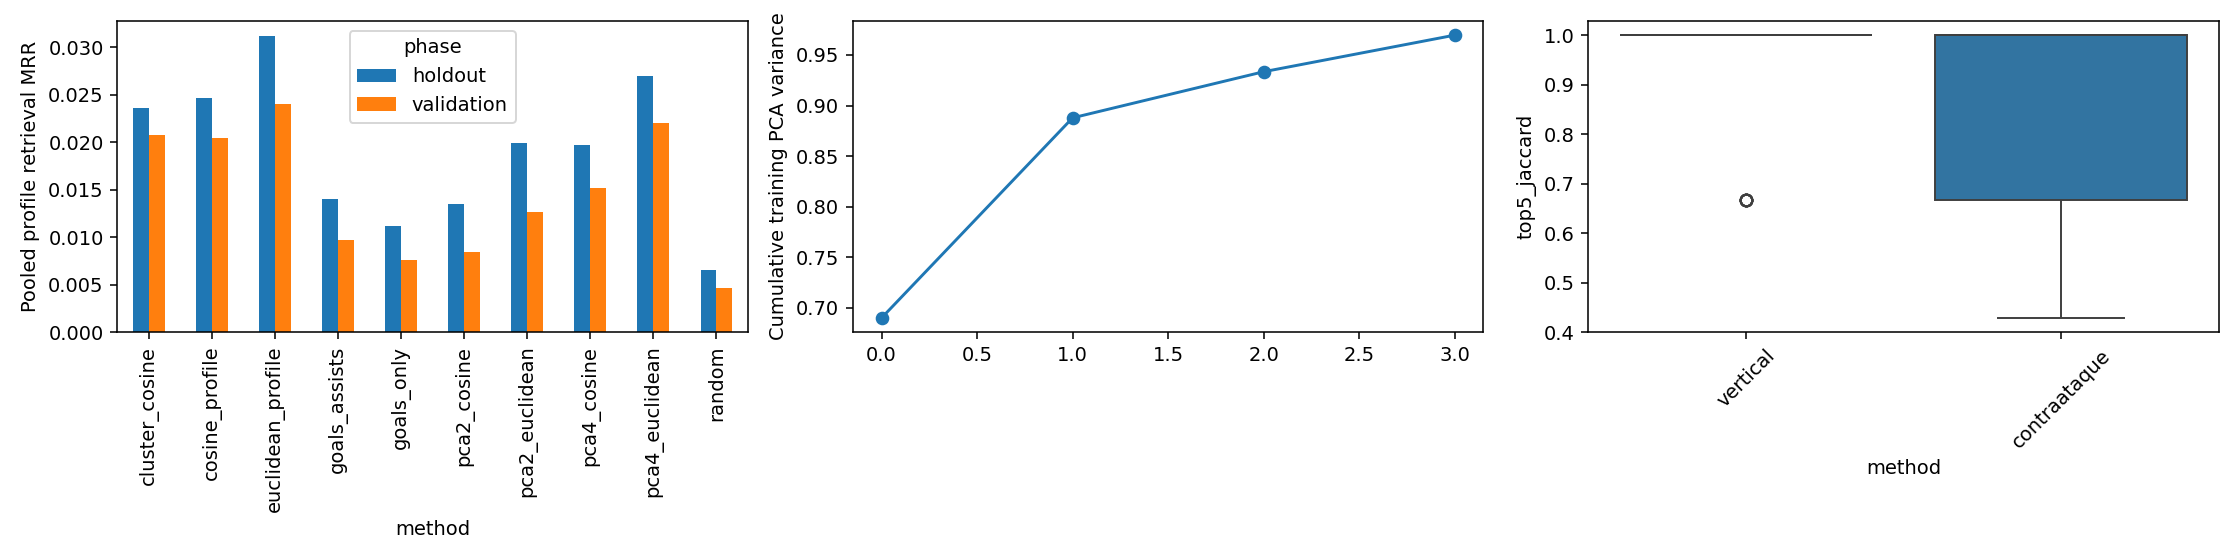

### core

,position_nmi,season_nmi,seed_ari_mean,league_nmi
0,0.375288,0.00006,1.0,0.00017


,gls_p90,ast_p90,sh_p90,sot_p90,crs_p90,int_p90,tklw_p90,fls_p90,fld_p90
0,0.428710,0.284523,0.470308,0.473254,0.126327,-0.380813,-0.269409,0.040077,0.234372
1,-0.142575,0.214500,0.029562,-0.041238,0.292889,0.087507,0.509199,0.577098,0.495299
2,-0.149824,0.482716,-0.089466,-0.110480,0.689324,0.010242,0.033296,-0.476518,-0.144486
3,-0.349431,-0.207464,-0.203606,-0.261218,0.114045,-0.401886,-0.497511,-0.046281,0.548625


,adjusted_rand_reference,adjusted_rand_out_of_bag
count,30.000000,30.000000
mean,0.983005,0.981926
std,0.008434,0.009360
min,0.967773,0.963394
25%,0.977380,0.974453
50%,0.983261,0.980747
75%,0.989191,0.988347
max,0.998916,1.000000


,mean,min,max
component,,,
1,0.999656,0.998975,0.999904
2,0.951672,0.717572,0.999360
3,0.950982,0.709880,0.999194
4,0.991864,0.967653,0.999027


mean       min  max
kind     method                                    
neighbor euclidean_profile  0.974074  0.666667  1.0
style    contraataque       0.966667  0.666667  1.0
         desborde_banda     0.962963  0.666667  1.0
         posesion           0.966667  0.666667  1.0
         presion_alta       0.955556  0.666667  1.0
         solidez_defensiva  0.937037  0.666667  1.0
         vertical           0.903704  0.666667  1.0

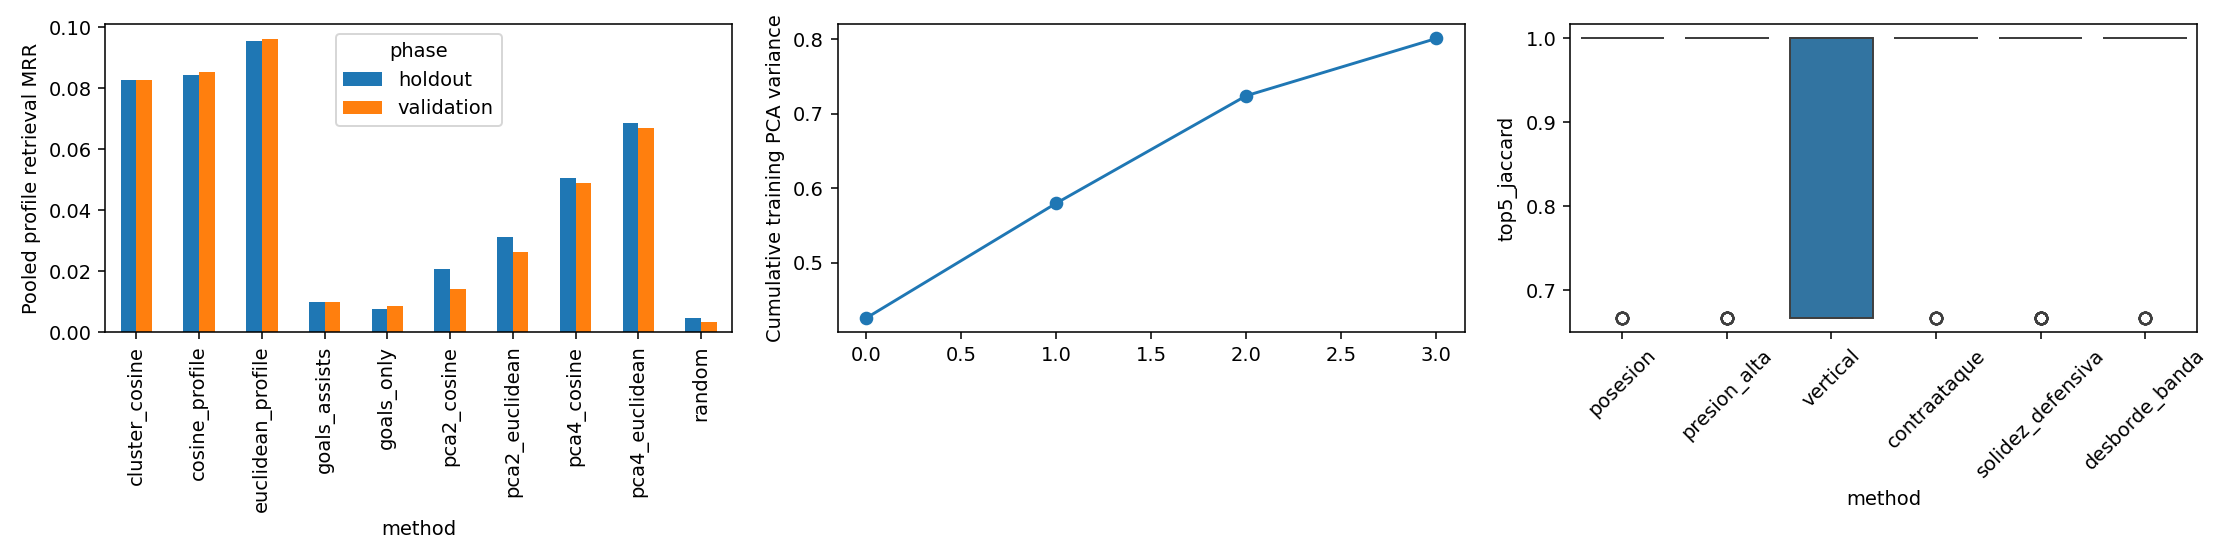

### attack_on_core

,position_nmi,season_nmi,seed_ari_mean,league_nmi
0,0.313311,0.000002,1.0,0.001389


,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,0.428194,0.296568,0.454850,0.458617,0.445064,0.336745
1,-0.285023,0.664968,-0.130680,-0.195688,-0.277561,0.586659
2,0.576337,0.439347,-0.512839,-0.259545,0.192332,-0.327798
3,0.371002,-0.526018,-0.339122,-0.193903,0.043115,0.656659


,adjusted_rand_reference,adjusted_rand_out_of_bag
count,30.000000,30.000000
mean,0.980279,0.981020
std,0.013174,0.013392
min,0.948523,0.954235
25%,0.975052,0.975487
50%,0.981867,0.982589
75%,0.989795,0.991366
max,0.998895,1.000000


,mean,min,max
component,,,
1,0.999885,0.999545,0.999981
2,0.999647,0.997936,0.999967
3,0.992061,0.971652,0.999891
4,0.992841,0.973149,0.999768


mean       min  max
kind     method                                    
neighbor euclidean_profile  0.974074  0.666667  1.0
style    contraataque       0.970370  0.666667  1.0
         vertical           0.921693  0.428571  1.0

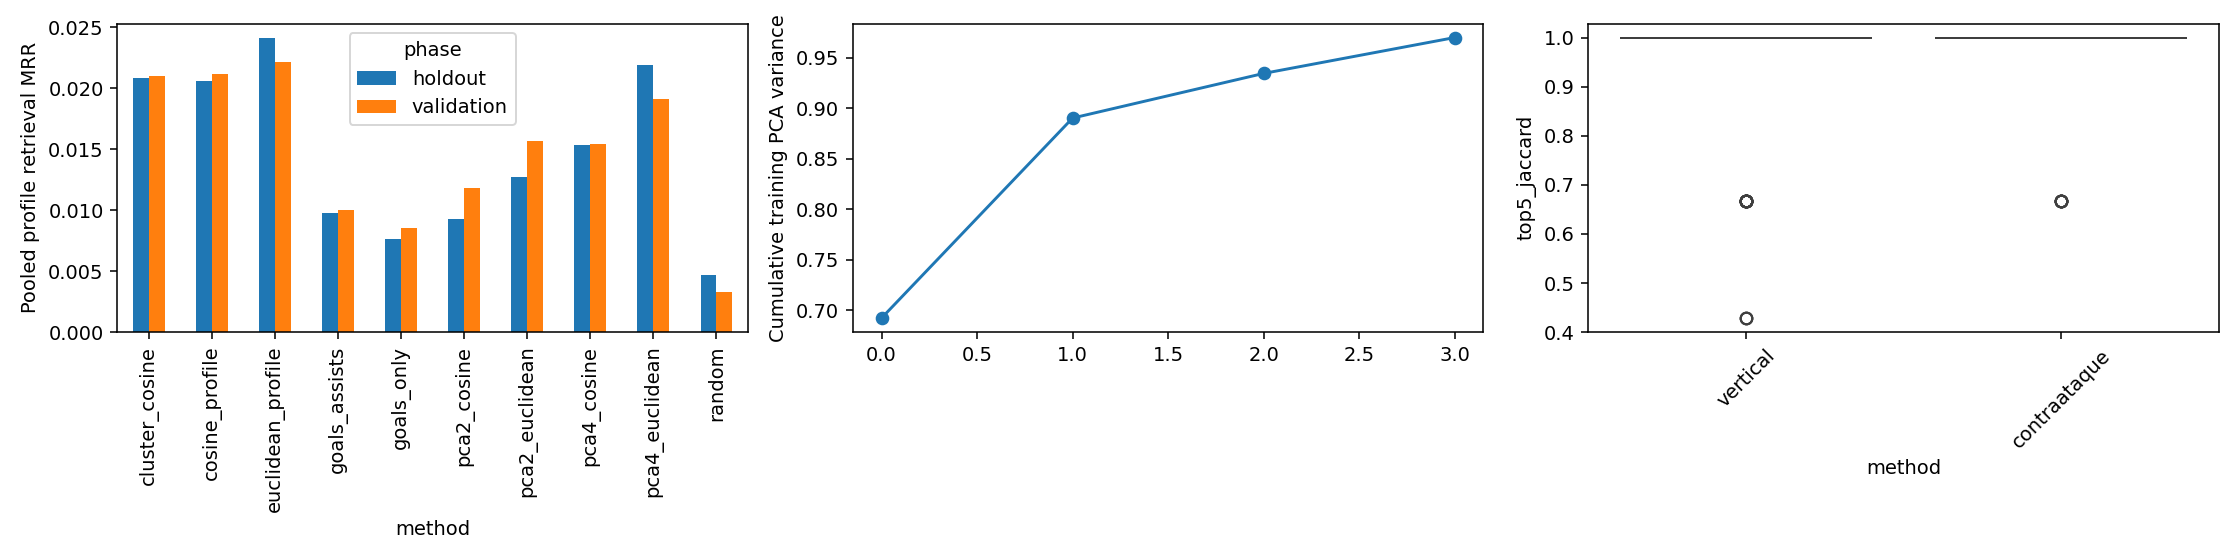

In [5]:
for name,info in report['experiments'].items():
    display(Markdown('### '+name))
    display(pd.DataFrame([info['cluster_diagnostics']]))
    display(pd.read_csv(folder/f'{name}_pca_loadings.csv'))
    clusters=pd.read_csv(folder/f'{name}_cluster_bootstrap.csv')
    loadings=pd.read_csv(folder/f'{name}_pca_loading_bootstrap.csv')
    display(clusters[['adjusted_rand_reference','adjusted_rand_out_of_bag']].describe())
    display(loadings.groupby('component').absolute_loading_cosine.agg(['mean','min','max']))
    display(pd.read_csv(folder/f'{name}_ranking_bootstrap.csv').groupby(['kind','method']).top5_jaccard.agg(['mean','min','max']))
    display(Image(filename=str(folder/f'{name}_evaluation.png')))


## Position/league diagnostics and qualitative recommendations

The per-league holdout slices use the same trained models and previously selected distance methods. Position slices retain actual returning players, candidate universe and bootstrap uncertainty. Qualitative alternatives apply known age, broad position and club restrictions; they are examples for human/video review, not validated club suitability, official budgets or outcomes.

In [6]:
for name,info in report['experiments'].items():
    league=pd.read_csv(folder/f'{name}_league_retrieval.csv')
    display(league[league.method.eq(info['selected_method'])][['league','queries','candidate_count','mrr','recall_at_5']])
    display(pd.read_csv(folder/f'{name}_position_retrieval.csv'))
    display(pd.read_csv(folder/f'{name}_qualitative.csv').head(8))


,league,queries,candidate_count,mrr,recall_at_5
2,La Liga,243,397,0.085233,0.106996
12,Premier League,234,361,0.120024,0.179487
22,Bundesliga,201,320,0.088043,0.104478
32,Serie A,243,392,0.091358,0.111111
42,Ligue 1,183,334,0.070054,0.092896


,phase,query_season,evaluation_season,position,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,recall_at_10,ndcg_at_10,target_available_fraction,mrr_delta_goals_assists,delta_ci_low,delta_ci_high,inference
0,holdout,2023-2024,2024-2025,DF,cluster_cosine,534,1804,0.022841,0.015140,0.032810,0.018727,0.033708,0.018692,0.977528,0.014435,0.006677,0.024163,post_hoc_conditional_subgroup_not_independent_...
1,holdout,2023-2024,2024-2025,DF,cosine_profile,534,1804,0.022812,0.015311,0.033221,0.018727,0.031835,0.018009,1.000000,0.014405,0.006694,0.024350,post_hoc_conditional_subgroup_not_independent_...
2,holdout,2023-2024,2024-2025,DF,euclidean_profile,534,1804,0.024339,0.016520,0.033646,0.026217,0.035581,0.019481,1.000000,0.015933,0.008015,0.025256,post_hoc_conditional_subgroup_not_independent_...
3,holdout,2023-2024,2024-2025,DF,goals_assists,534,1804,0.008406,0.006327,0.011140,0.008681,0.017362,0.006898,1.000000,0.000000,0.000000,0.000000,post_hoc_conditional_subgroup_not_independent_...
4,holdout,2023-2024,2024-2025,DF,goals_only,534,1804,0.007309,0.005718,0.009193,0.005853,0.012643,0.005105,1.000000,-0.001097,-0.003796,0.001514,post_hoc_conditional_subgroup_not_independent_...
5,holdout,2023-2024,2024-2025,DF,pca2_cosine,534,1804,0.011570,0.008853,0.014335,0.011236,0.022472,0.008757,1.000000,0.003164,-0.000551,0.006357,post_hoc_conditional_subgroup_not_independent_...
6,holdout,2023-2024,2024-2025,DF,pca2_euclidean,534,1804,0.015254,0.010751,0.021986,0.011236,0.020599,0.009793,1.000000,0.006848,0.001801,0.013387,post_hoc_conditional_subgroup_not_independent_...
7,holdout,2023-2024,2024-2025,DF,pca4_cosine,534,1804,0.015236,0.010853,0.020287,0.011236,0.028090,0.011719,1.000000,0.006830,0.002048,0.011968,post_hoc_conditional_subgroup_not_independent_...
8,holdout,2023-2024,2024-2025,DF,pca4_euclidean,534,1804,0.019304,0.013661,0.027216,0.018727,0.033708,0.015594,1.000000,0.010898,0.005031,0.018806,post_hoc_conditional_subgroup_not_independent_...
9,holdout,2023-2024,2024-2025,DF,random,534,1804,0.005050,0.002508,0.009668,0.003745,0.003745,0.002679,1.000000,-0.003356,-0.007250,0.001882,post_hoc_conditional_subgroup_not_independent_...


,reference,reference_entity,reference_club,position,season,rank,player,entity_id,team,age,...,method,similarity_score,budget_status,interpretation,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,Harry Kane,fbref:21a66f6a,Tottenham,FW,2022-2023,1,Jonathan David,fbref:ce50fd99,Lille,22.0,...,euclidean_profile,-1.291676,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.682249,0.113708,2.700569,1.250790,0.670878,0.173405
1,Harry Kane,fbref:21a66f6a,Tottenham,FW,2022-2023,2,Loïs Openda,fbref:8652a85c,Lens,22.0,...,euclidean_profile,-1.390312,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.750894,0.143027,3.682956,1.752086,0.661502,0.150179
2,Harry Kane,fbref:21a66f6a,Tottenham,FW,2022-2023,3,Lázaro,fbref:86ff856b,Almería,20.0,...,euclidean_profile,-1.407536,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.754190,0.000000,3.142458,1.508380,0.502793,0.100559
3,Harry Kane,fbref:21a66f6a,Tottenham,FW,2022-2023,4,Deniz Undav,fbref:dd549382,Brighton,26.0,...,euclidean_profile,-1.470838,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.716561,0.000000,3.869427,1.719745,0.644904,0.157643
4,Harry Kane,fbref:21a66f6a,Tottenham,FW,2022-2023,5,Christopher Nkunku,fbref:7c56da38,RB Leipzig,24.0,...,euclidean_profile,-1.484404,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.759093,0.189773,3.321033,1.186083,0.683184,0.204006
5,Birama Touré,fbref:a4b798a9,Auxerre,MF,2022-2023,1,Iddrisu Baba,fbref:bfd381b3,Mallorca,26.0,...,euclidean_profile,-0.406449,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.000000,0.000000,0.633431,0.105572,0.031672,0.010557
6,Birama Touré,fbref:a4b798a9,Auxerre,MF,2022-2023,2,Roméo Lavia,fbref:ecad9aa5,Southampton,18.0,...,euclidean_profile,-0.424067,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.040522,0.000000,0.486267,0.121567,0.016209,0.024313
7,Birama Touré,fbref:a4b798a9,Auxerre,MF,2022-2023,3,Flynn Downes,fbref:69fdb896,West Ham,23.0,...,euclidean_profile,-0.425773,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.000000,0.000000,0.472441,0.118110,0.047244,0.011811


,league,queries,candidate_count,mrr,recall_at_5
2,La Liga,245,391,0.229776,0.338776
12,Premier League,232,371,0.182647,0.262931
22,Bundesliga,210,324,0.206611,0.300000
32,Serie A,240,390,0.221866,0.300000
42,Ligue 1,184,334,0.234593,0.288043


,phase,query_season,evaluation_season,position,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,recall_at_10,ndcg_at_10,target_available_fraction,mrr_delta_goals_assists,delta_ci_low,delta_ci_high,inference
0,holdout,2022-2023,2023-2024,DF,cluster_cosine,552,1810,0.072690,0.058404,0.090882,0.079710,0.141304,0.077164,0.961957,0.062376,0.047686,0.080586,post_hoc_conditional_subgroup_not_independent_...
1,holdout,2022-2023,2023-2024,DF,cosine_profile,552,1810,0.072790,0.058590,0.091094,0.077899,0.143116,0.077474,1.000000,0.062475,0.047800,0.080703,post_hoc_conditional_subgroup_not_independent_...
2,holdout,2022-2023,2023-2024,DF,euclidean_profile,552,1810,0.075090,0.060604,0.091827,0.086957,0.143116,0.079160,1.000000,0.064775,0.050152,0.082162,post_hoc_conditional_subgroup_not_independent_...
3,holdout,2022-2023,2023-2024,DF,goals_assists,552,1810,0.010315,0.006078,0.016008,0.008344,0.011254,0.006747,1.000000,0.000000,0.000000,0.000000,post_hoc_conditional_subgroup_not_independent_...
4,holdout,2022-2023,2023-2024,DF,goals_only,552,1810,0.007024,0.004843,0.011032,0.004105,0.006398,0.003895,1.000000,-0.003291,-0.007342,-0.000600,post_hoc_conditional_subgroup_not_independent_...
5,holdout,2022-2023,2023-2024,DF,pca2_cosine,552,1810,0.016407,0.012749,0.020712,0.019928,0.036232,0.014660,1.000000,0.006092,-0.000887,0.012100,post_hoc_conditional_subgroup_not_independent_...
6,holdout,2022-2023,2023-2024,DF,pca2_euclidean,552,1810,0.031090,0.022960,0.040898,0.034420,0.052536,0.027997,1.000000,0.020775,0.011008,0.030533,post_hoc_conditional_subgroup_not_independent_...
7,holdout,2022-2023,2023-2024,DF,pca4_cosine,552,1810,0.049360,0.038534,0.061349,0.052536,0.106884,0.052003,1.000000,0.039045,0.027826,0.051179,post_hoc_conditional_subgroup_not_independent_...
8,holdout,2022-2023,2023-2024,DF,pca4_euclidean,552,1810,0.057308,0.045286,0.070354,0.074275,0.119565,0.060949,1.000000,0.046993,0.034033,0.059650,post_hoc_conditional_subgroup_not_independent_...
9,holdout,2022-2023,2023-2024,DF,random,552,1810,0.005789,0.003237,0.009142,0.009058,0.012681,0.005609,1.000000,-0.004525,-0.010723,0.001061,post_hoc_conditional_subgroup_not_independent_...


,reference,reference_entity,reference_club,position,season,rank,player,entity_id,team,age,...,interpretation,gls_p90,ast_p90,sh_p90,sot_p90,crs_p90,int_p90,tklw_p90,fls_p90,fld_p90
0,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,1,Randal Kolo Muani,fbref:c0b3669f,Nantes,22.0,...,descriptive alternatives; no transfer/relevanc...,0.366350,0.122117,1.648575,0.793758,0.946404,0.183175,0.427408,1.801221,2.198100
1,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,2,Kasper Dolberg,fbref:cc83b74d,Nice,23.0,...,descriptive alternatives; no transfer/relevanc...,0.361930,0.120643,2.292225,0.784182,0.301609,0.361930,0.241287,1.809651,1.749330
2,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,3,Breel Embolo,fbref:0b4f388a,M'Gladbach,24.0,...,descriptive alternatives; no transfer/relevanc...,0.373961,0.124654,1.994460,0.955679,0.083102,0.249307,0.457064,1.703601,2.950139
3,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,4,Lucas Boyé,fbref:d49f3e6b,Elche,25.0,...,descriptive alternatives; no transfer/relevanc...,0.367776,0.157618,2.574431,0.840630,0.367776,0.105079,0.683012,2.049037,2.101576
4,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,5,Thomas Henry,fbref:9ef42479,Venezia,26.0,...,descriptive alternatives; no transfer/relevanc...,0.382979,0.085106,2.170213,1.021277,0.212766,0.085106,0.170213,2.127660,2.936170
5,Seko Fofana,fbref:5313ed43,Lens,MF,2021-2022,1,Marko Pjaca,fbref:2c38b327,Torino,26.0,...,descriptive alternatives; no transfer/relevanc...,0.234987,0.000000,1.644909,0.861619,1.331593,0.313316,0.313316,0.861619,1.096606
6,Seko Fofana,fbref:5313ed43,Lens,MF,2021-2022,2,Giacomo Raspadori,fbref:6e058f06,Sassuolo,21.0,...,descriptive alternatives; no transfer/relevanc...,0.328467,0.131387,2.332117,0.821168,2.069343,0.295620,0.591241,0.952555,1.083942
7,Seko Fofana,fbref:5313ed43,Lens,MF,2021-2022,3,Mohamed Elyounoussi,fbref:68dc0dac,Southampton,26.0,...,descriptive alternatives; no transfer/relevanc...,0.176298,0.088149,1.895201,0.749265,1.278159,0.528893,0.749265,1.234084,0.793340


,league,queries,candidate_count,mrr,recall_at_5
2,La Liga,245,391,0.065916,0.081633
12,Premier League,232,371,0.078099,0.099138
22,Bundesliga,210,324,0.064849,0.066667
32,Serie A,240,390,0.078384,0.095833
42,Ligue 1,184,334,0.086803,0.108696


,phase,query_season,evaluation_season,position,method,queries,candidate_count,mrr,mrr_ci_low,mrr_ci_high,recall_at_5,recall_at_10,ndcg_at_10,target_available_fraction,mrr_delta_goals_assists,delta_ci_low,delta_ci_high,inference
0,holdout,2022-2023,2023-2024,DF,cluster_cosine,552,1810,0.016954,0.011475,0.023392,0.012681,0.030797,0.013992,0.965580,0.006640,0.001056,0.012521,post_hoc_conditional_subgroup_not_independent_...
1,holdout,2022-2023,2023-2024,DF,cosine_profile,552,1810,0.016857,0.011340,0.023294,0.012681,0.030797,0.013912,1.000000,0.006542,0.000987,0.012486,post_hoc_conditional_subgroup_not_independent_...
2,holdout,2022-2023,2023-2024,DF,euclidean_profile,552,1810,0.016625,0.011812,0.022848,0.014493,0.021739,0.010750,1.000000,0.006310,0.000765,0.011491,post_hoc_conditional_subgroup_not_independent_...
3,holdout,2022-2023,2023-2024,DF,goals_assists,552,1810,0.010315,0.006078,0.016008,0.008344,0.011254,0.006747,1.000000,0.000000,0.000000,0.000000,post_hoc_conditional_subgroup_not_independent_...
4,holdout,2022-2023,2023-2024,DF,goals_only,552,1810,0.007024,0.004843,0.011032,0.004105,0.006398,0.003895,1.000000,-0.003291,-0.007342,-0.000600,post_hoc_conditional_subgroup_not_independent_...
5,holdout,2022-2023,2023-2024,DF,pca2_cosine,552,1810,0.008781,0.006085,0.013073,0.003623,0.009058,0.004205,1.000000,-0.001534,-0.007563,0.004984,post_hoc_conditional_subgroup_not_independent_...
6,holdout,2022-2023,2023-2024,DF,pca2_euclidean,552,1810,0.008953,0.007470,0.010656,0.003623,0.009058,0.003094,1.000000,-0.001362,-0.007009,0.002806,post_hoc_conditional_subgroup_not_independent_...
7,holdout,2022-2023,2023-2024,DF,pca4_cosine,552,1810,0.014625,0.010346,0.020421,0.009058,0.023551,0.010667,1.000000,0.004310,-0.000289,0.009524,post_hoc_conditional_subgroup_not_independent_...
8,holdout,2022-2023,2023-2024,DF,pca4_euclidean,552,1810,0.016483,0.011259,0.022834,0.012681,0.023551,0.011485,1.000000,0.006168,-0.000006,0.012121,post_hoc_conditional_subgroup_not_independent_...
9,holdout,2022-2023,2023-2024,DF,random,552,1810,0.005789,0.003237,0.009142,0.009058,0.012681,0.005609,1.000000,-0.004525,-0.010723,0.001061,post_hoc_conditional_subgroup_not_independent_...


,reference,reference_entity,reference_club,position,season,rank,player,entity_id,team,age,...,method,similarity_score,budget_status,interpretation,gls_p90,ast_p90,sh_p90,sot_p90,xg_p90,xag_p90
0,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,1,Ollie Watkins,fbref:aed3a70f,Aston Villa,25.0,...,euclidean_profile,-0.537999,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.335366,0.060976,2.317073,0.945122,0.353659,0.103659
1,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,2,Kasper Dolberg,fbref:cc83b74d,Nice,23.0,...,euclidean_profile,-0.547375,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.361930,0.120643,2.292225,0.784182,0.386059,0.072386
2,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,3,Santi Mina,fbref:0b90bb97,Celta Vigo,25.0,...,euclidean_profile,-0.648106,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.266160,0.114068,2.243346,0.798479,0.323194,0.098859
3,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,4,Stephy Mavididi,fbref:30144daa,Montpellier,23.0,...,euclidean_profile,-0.657970,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.313180,0.117442,2.348847,0.900391,0.297521,0.129187
4,João Pedro,fbref:81255c03,Cagliari,FW,2021-2022,5,Riccardo Orsolini,fbref:e14ec482,Bologna,24.0,...,euclidean_profile,-0.686731,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.302521,0.151261,2.571429,0.806723,0.322689,0.105882
5,Seko Fofana,fbref:5313ed43,Lens,MF,2021-2022,1,Ajdin Hrustic,fbref:1f2d714c,Eint Frankfurt,25.0,...,euclidean_profile,-0.680665,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.186722,0.000000,2.707469,0.746888,0.112033,0.056017
6,Seko Fofana,fbref:5313ed43,Lens,MF,2021-2022,2,Ondrej Duda,fbref:79ca3e23,Köln,26.0,...,euclidean_profile,-0.944531,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.111732,0.000000,2.346369,0.782123,0.217877,0.122905
7,Seko Fofana,fbref:5313ed43,Lens,MF,2021-2022,3,Marko Pjaca,fbref:2c38b327,Torino,26.0,...,euclidean_profile,-1.106126,not_applied; dated valuations unavailable,descriptive alternatives; no transfer/relevanc...,0.234987,0.000000,1.644909,0.861619,0.156658,0.093995


## Cross-source review and realistic budget scenarios

Existing source-ID mapping plus normalized-name/birth-year agreement proposes additional identities across all five leagues. Every proposal remains unreviewed; current profile evidence does not establish historical known-at information. Profile enrichment and dated reported values remain separate private review outputs and are rejected by model-use guards. A reported market assessment is not a fee; latest zero is unknown, not free. Fifty one-vacancy cases across five league pools use observed model profiles with age/position/style/minutes/own-club/value constraints and requirement sensitivity. Empty pools are never relaxed and are not failures. Offline batches create no human process events.

In [7]:
display(pd.read_csv(folder/'price_coverage.csv'))
display(Markdown('Reported values are provisional post-ranking screening; no historical transfer-affordability validation is claimed.'))

,model,league,season,players,provisional_links,positive_values,historical_budget_eligible
0,core,Bundesliga,2023-2024,324,304,302,False
1,core,La Liga,2023-2024,391,334,332,False
2,core,Ligue 1,2023-2024,334,300,299,False
3,core,Premier League,2023-2024,371,344,344,False
4,core,Serie A,2023-2024,390,351,350,False
5,core,Bundesliga,2022-2023,328,307,305,False
6,core,La Liga,2022-2023,385,336,334,False
7,core,Ligue 1,2022-2023,377,352,350,False
8,core,Premier League,2022-2023,377,357,357,False
9,core,Serie A,2022-2023,394,357,357,False


Reported values are provisional post-ranking screening; no historical transfer-affordability validation is claimed.

## MLflow, app and remaining validation limits

Three actual model-refit runs are separate from the earlier frozen-model diagnostic. Each records dataset/code version, owner/project/environment, evaluation plots, PCA/clustering/robustness tables and model artifacts, with checksum-verified portable exports. Serving keeps European-trained and original La Liga-trained choices. Historical actual-transfer success, genuine club-process outcomes, individually approved identities, provider publication dates and advanced Segunda coverage remain incomplete. No valuation prediction or transfer-success metric is invented.

In [8]:
for name,info in report['experiments'].items():
    run=json.loads((folder/'mlflow_export'/name/'run.json').read_text())
    assert run['status']=='FINISHED' and run['run_id']==info['mlflow_run_id']
    assert run['tags']['dataset']==report['dataset_version']
    display(pd.DataFrame([dict(model=name,run_id=run['run_id'],status=run['status'],original_logged_artifacts=info['original_exported_artifact_count'])]))
display(Markdown('; '.join(report['limits'])))


,model,run_id,status,original_logged_artifacts
0,offensive,77dc5b4e615245ae910aec3a75360136,FINISHED,26


,model,run_id,status,original_logged_artifacts
0,core,85b7e82117814713b9094a5385308f6f,FINISHED,26


,model,run_id,status,original_logged_artifacts
0,attack_on_core,8c9b96e63c57430f9662f917908e571b,FINISHED,26


Future seasons never enter fitting; partial2025/26 excluded; Transfermarkt fields excluded from fitting; cross-source price identities provisional; Profile retrieval and descriptive tactical affinity are not transfer-success or club relevance labels; Core/offensive periods differ; attack_on_core is a matched-cohort feature comparison; Core advanced2024/25 sparse; advancedSegunda missing; Outliers flagged, never automatically removed